# Customer Segmentation of E-Commerce Big Data using PySpark K-Means (RFM Analysis)

**Course:** Big Data Analytics (Sem VII) · Adani University · **Reference topic #34:** Customer Segmentation Using Scalable Clustering Techniques
**Author:** Rohan Upadhyay

**Dataset:** *eCommerce Events History in Cosmetics Shop* (REES46 / Kaggle): 5 monthly CSV files (Oct 2019 – Feb 2020), **≈2.3 GB, ≈20 million clickstream events** (`view`, `cart`, `remove_from_cart`, `purchase`).

**Goal:** use Apache Spark to process the full event log, compute each buyer's **Recency, Frequency and Monetary (RFM)** values from the purchase events, and cluster buyers with **Spark MLlib K-Means** into marketing segments.

| Step | Spark component | Syllabus unit |
|---|---|---|
| 1. Ingest 5 CSVs (2.3 GB) | `SparkSession`, `spark.read.csv` with an explicit schema | Unit 1, 2, 4 |
| 2. Clean | DataFrame transformations (`filter`, `withColumn`, `dropDuplicates`) | Unit 4 |
| 3. EDA | SparkSQL on temp view `events` | Unit 4 |
| 4. RFM features | `groupBy().agg()` on purchase events | Unit 4 / 5 |
| 5. Scale | MLlib `VectorAssembler` → `StandardScaler` | Unit 5 |
| 6. Choose k | MLlib `KMeans` + `ClusteringEvaluator` (elbow + Silhouette) | Unit 5 |
| 7. Final model + profiling | `KMeans(k, seed=42)` | Unit 5 / 6 |

> **Colab:** add your Kaggle API token as a Colab secret named `KAGGLE_API_TOKEN` (🔑 icon on the left, enable *Notebook access*), then *Runtime → Run all*. The notebook downloads the dataset itself.

## 0. Setup: install PySpark and start a SparkSession

In [1]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install pyspark "kaggle>=1.8"
print("Running on Colab:", IN_COLAB)

Running on Colab: False


In [2]:
import json, time, glob, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, LongType, DoubleType

spark = (SparkSession.builder
         .appName("BDA-Customer-Segmentation-RFM")
         .master("local[*]")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "32")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)
print("Default parallelism (cores used):", spark.sparkContext.defaultParallelism)

os.makedirs("outputs", exist_ok=True)
RESULTS = {}   # key numbers collected for the slides

# Chart style: one validated categorical palette, used in fixed order
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
                     "axes.edgecolor": "#52514e", "text.color": "#0b0b0b"})

Spark version: 3.5.3
Default parallelism (cores used): 24


## 1. Ingest the data (≈2.3 GB, 5 files)

The dataset is downloaded with the Kaggle CLI (only if it isn't already on disk). Spark reads **all five CSV files at once** into one DataFrame (split into many partitions that are processed in parallel). We give an **explicit schema**, so Spark does not need an extra full pass over 2.3 GB to infer types.

In [3]:
DATA_DIR = "data/cosmetics"
if not glob.glob(f"{DATA_DIR}/*.csv"):
    if IN_COLAB:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    os.makedirs(DATA_DIR, exist_ok=True)
    print("Downloading dataset from Kaggle (~0.5 GB zipped, ~2.3 GB unzipped) ...")
    subprocess.run(["kaggle", "datasets", "download", "-d", "mkechinov/ecommerce-events-history-in-cosmetics-shop",
                    "-p", DATA_DIR, "--unzip"], check=True)

files = sorted(glob.glob(f"{DATA_DIR}/*.csv"))
sizes = {os.path.basename(f): os.path.getsize(f) for f in files}
total_gb = sum(sizes.values()) / 1024**3
for name, b in sizes.items():
    print(f"  {name:15s} {b/1024**2:8.1f} MB")
print(f"  {'TOTAL':15s} {total_gb:8.2f} GB in {len(files)} files")
RESULTS.update(data_size_gb=round(total_gb, 2), n_files=len(files))

  2019-Dec.csv       396.1 MB
  2019-Nov.csv       520.6 MB
  2019-Oct.csv       460.2 MB
  2020-Feb.csv       466.2 MB
  2020-Jan.csv       478.5 MB
  TOTAL               2.27 GB in 5 files


In [4]:
schema = StructType([
    StructField("event_time", StringType()),     # e.g. '2019-10-01 00:00:00 UTC'
    StructField("event_type", StringType()),     # view | cart | remove_from_cart | purchase
    StructField("product_id", LongType()),
    StructField("category_id", LongType()),
    StructField("category_code", StringType()),
    StructField("brand", StringType()),
    StructField("price", DoubleType()),
    StructField("user_id", LongType()),
    StructField("user_session", StringType()),
])
raw = spark.read.csv(files, header=True, schema=schema)   # all 5 monthly files in one DataFrame
raw.printSchema()

t0 = time.time()
raw_count = raw.count()            # action -> Spark actually scans the 2.3 GB here
RESULTS.update(raw_rows=raw_count, raw_partitions=raw.rdd.getNumPartitions(),
               scan_seconds=round(time.time() - t0, 1))
print(f"Raw events: {raw_count:,}   Columns: {len(raw.columns)}   "
      f"Partitions: {RESULTS['raw_partitions']}   Full scan: {RESULTS['scan_seconds']} s")
raw.show(5, truncate=False)

root
 |-- event_time: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: long (nullable = true)
 |-- category_id: long (nullable = true)
 |-- category_code: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- price: double (nullable = true)
 |-- user_id: long (nullable = true)
 |-- user_session: string (nullable = true)



Raw events: 20,692,840   Columns: 9   Partitions: 25   Full scan: 6.3 s


+-----------------------+----------------+----------+-------------------+-------------+---------+-----+---------+------------------------------------+
|event_time             |event_type      |product_id|category_id        |category_code|brand    |price|user_id  |user_session                        |
+-----------------------+----------------+----------+-------------------+-------------+---------+-----+---------+------------------------------------+
|2019-12-01 00:00:00 UTC|remove_from_cart|5712790   |1487580005268456287|NULL         |f.o.x    |6.27 |576802932|51d85cb0-897f-48d2-918b-ad63965c12dc|
|2019-12-01 00:00:00 UTC|view            |5764655   |1487580005411062629|NULL         |cnd      |29.05|412120092|8adff31e-2051-4894-9758-224bfa8aec18|
|2019-12-01 00:00:02 UTC|cart            |4958      |1487580009471148064|NULL         |runail   |1.19 |494077766|c99a50e8-2fac-4c4d-89ec-41c05f114554|
|2019-12-01 00:00:05 UTC|view            |5848413   |1487580007675986893|NULL         |freedec

## 2. Clean the data

Rules:
* parse `event_time` to a timestamp (strip the ` UTC` suffix)
* drop rows with no `user_id` / `user_session`, and rows with `price <= 0`
* drop exact duplicate events (the raw log contains repeated rows)

These are **transformations**: Spark only builds a plan (DAG). Nothing runs until an **action** such as `count()` (*lazy evaluation*). The cleaned DataFrame is **cached**, because every later step reuses it.

In [5]:
events = (raw
          .withColumn("event_time", F.to_timestamp(F.regexp_replace("event_time", " UTC", "")))
          .filter(F.col("user_id").isNotNull() & F.col("user_session").isNotNull())
          .filter(F.col("price") > 0)
          .dropDuplicates()
          .select("event_time", "event_type", "product_id", "brand", "price", "user_id", "user_session")
          .cache())

events.explain()                 # the physical plan Spark built (nothing has run yet)
t0 = time.time()
clean_count = events.count()     # action
RESULTS.update(clean_rows=clean_count, removed_rows=raw_count - clean_count,
               removed_pct=round(100 * (raw_count - clean_count) / raw_count, 1),
               clean_seconds=round(time.time() - t0, 1))
print(f"Rows before cleaning : {raw_count:,}")
print(f"Rows after cleaning  : {clean_count:,}  ({RESULTS['removed_pct']}% removed: nulls, price<=0, duplicates)")
print(f"Clean + cache time   : {RESULTS['clean_seconds']} s")
events.show(5, truncate=False)

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- InMemoryTableScan [event_time#88, event_type#1, product_id#2L, brand#5, price#6, user_id#7L, user_session#8]
      +- InMemoryRelation [event_time#88, event_type#1, product_id#2L, brand#5, price#6, user_id#7L, user_session#8], StorageLevel(disk, memory, deserialized, 1 replicas)
            +- AdaptiveSparkPlan isFinalPlan=false
               +- HashAggregate(keys=[user_session#8, price#6, brand#5, user_id#7L, event_time#88, event_type#1, product_id#2L, category_id#3L, category_code#4], functions=[])
                  +- Exchange hashpartitioning(user_session#8, price#6, brand#5, user_id#7L, event_time#88, event_type#1, product_id#2L, category_id#3L, category_code#4, 32), ENSURE_REQUIREMENTS, [plan_id=60]
                     +- HashAggregate(keys=[user_session#8, knownfloatingpointnormalized(normalizenanandzero(price#6)) AS price#6, brand#5, user_id#7L, event_time#88, event_type#1, product_id#2L, category_id#3L, category_code

Rows before cleaning : 20,692,840
Rows after cleaning  : 19,493,208  (5.8% removed: nulls, price<=0, duplicates)
Clean + cache time   : 33.3 s
+-------------------+----------------+----------+--------+------+---------+------------------------------------+
|event_time         |event_type      |product_id|brand   |price |user_id  |user_session                        |
+-------------------+----------------+----------+--------+------+---------+------------------------------------+
|2019-12-01 00:25:55|remove_from_cart|5885597   |polarus |102.38|407458156|5aa8f606-eca9-4555-ae53-80911cdae263|
|2019-12-01 03:23:14|view            |5856191   |runail  |24.44 |408499887|975c4e5d-dd41-4731-aa7d-4e7d85b1b065|
|2019-12-01 03:23:28|remove_from_cart|5856191   |runail  |24.44 |438996965|4b3ae663-6365-4b0d-b534-8b16ad4082d2|
|2019-12-01 03:23:32|view            |5854574   |jessnail|21.43 |408499887|975c4e5d-dd41-4731-aa7d-4e7d85b1b065|
|2019-12-01 07:39:23|remove_from_cart|5753703   |yoko    |3.44  |5

## 3. Exploratory analysis with SparkSQL

In [6]:
events.createOrReplaceTempView("events")

overview = spark.sql('''
    SELECT COUNT(*)                     AS events,
           COUNT(DISTINCT user_id)      AS users,
           COUNT(DISTINCT user_session) AS sessions,
           COUNT(DISTINCT product_id)   AS products,
           COUNT(DISTINCT brand)        AS brands,
           MIN(event_time) AS first_event, MAX(event_time) AS last_event
    FROM events''')
overview.show(truncate=False)
o = overview.first()
RESULTS.update(users=o.users, sessions=o.sessions, products=o.products, brands=o.brands,
               first_date=str(o.first_event.date()), last_date=str(o.last_event.date()))

+--------+-------+--------+--------+------+-------------------+-------------------+
|events  |users  |sessions|products|brands|first_event        |last_event         |
+--------+-------+--------+--------+------+-------------------+-------------------+
|19493208|1637770|4520284 |53903   |273   |2019-10-01 00:00:00|2020-02-29 23:59:59|
+--------+-------+--------+--------+------+-------------------+-------------------+



In [7]:
funnel = spark.sql('''
    SELECT event_type, COUNT(*) AS events, COUNT(DISTINCT user_id) AS users
    FROM events GROUP BY event_type ORDER BY events DESC''')
funnel.show()

monthly = spark.sql('''
    SELECT DATE_FORMAT(event_time, 'yyyy-MM') AS month,
           ROUND(SUM(price), 0)               AS revenue,
           COUNT(DISTINCT user_id)            AS buyers,
           COUNT(DISTINCT user_session)       AS orders
    FROM events WHERE event_type = 'purchase'
    GROUP BY month ORDER BY month''')
monthly.show()

top_brands = spark.sql('''
    SELECT brand, ROUND(SUM(price), 0) AS revenue, COUNT(*) AS units
    FROM events WHERE event_type = 'purchase' AND brand IS NOT NULL
    GROUP BY brand ORDER BY revenue DESC LIMIT 10''')
top_brands.show()

+----------------+-------+-------+
|      event_type| events|  users|
+----------------+-------+-------+
|            view|9626268|1596359|
|            cart|5612289| 397390|
|remove_from_cart|2968669| 183002|
|        purchase|1285982| 110518|
+----------------+-------+-------+



+-------+---------+------+------+
|  month|  revenue|buyers|orders|
+-------+---------+------+------+
|2019-10|1210922.0| 25762| 29326|
|2019-11|1530831.0| 31524| 36568|
|2019-12|1077689.0| 25613| 28894|
|2020-01|1321825.0| 28220| 32385|
|2020-02|1207001.0| 25759| 29401|
+-------+---------+------+------+



+--------+--------+------+
|   brand| revenue| units|
+--------+--------+------+
|  runail|343306.0|111350|
| grattol|266296.0| 49542|
|   irisk|223771.0| 73747|
|     uno|190719.0| 17586|
|  strong|151942.0|   850|
|  masura|138568.0| 49566|
|jessnail|134775.0|  9661|
|ingarden|124570.0| 27401|
|   estel|121714.0| 19424|
|     cnd|106328.0|  7686|
+--------+--------+------+



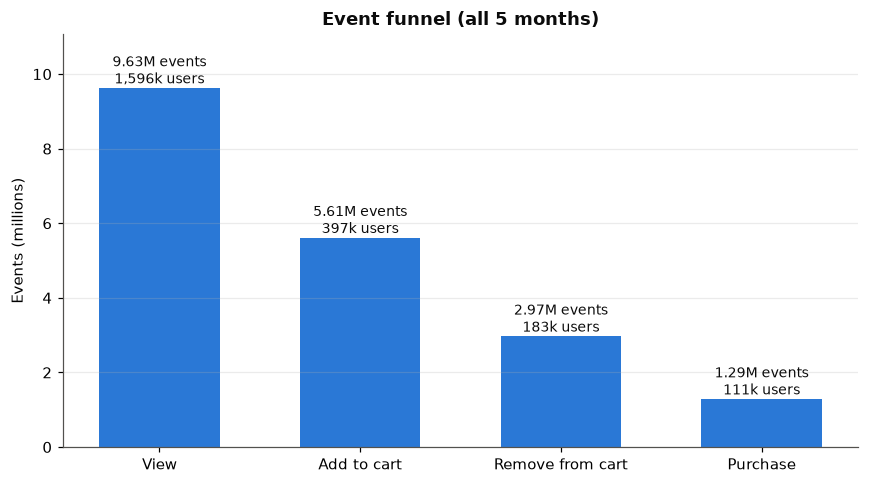

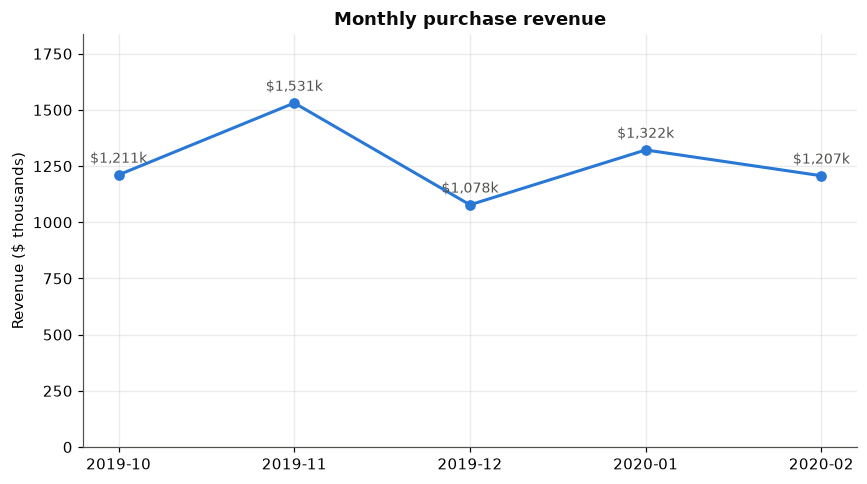

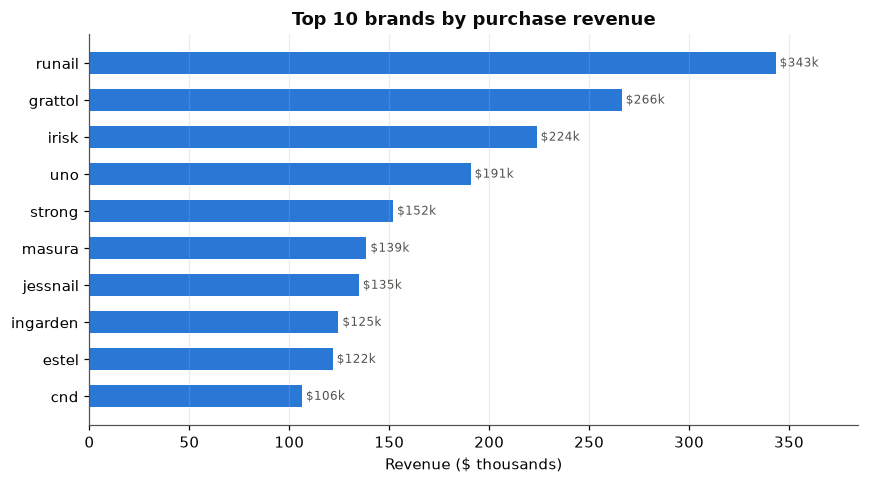

In [8]:
# Only the small aggregated results are brought to the driver for plotting
fu, mo, tb = funnel.toPandas(), monthly.toPandas(), top_brands.toPandas()
fu = fu.set_index("event_type").loc[["view", "cart", "remove_from_cart", "purchase"]].reset_index()
ev = dict(zip(fu.event_type, fu.events)); us = dict(zip(fu.event_type, fu.users))
RESULTS.update(event_counts={k: int(v) for k, v in ev.items()}, user_counts={k: int(v) for k, v in us.items()},
               view_to_purchase_user_pct=round(100 * us["purchase"] / us["view"], 1),
               revenue=float(mo.revenue.sum()), purchase_events=int(ev["purchase"]))

fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["View", "Add to cart", "Remove from cart", "Purchase"]
ax.bar(labels, fu.events / 1e6, color=PALETTE[0], width=0.6)
for i, (e, u) in enumerate(zip(fu.events, fu.users)):
    ax.text(i, e / 1e6, f"{e/1e6:.2f}M events\n{u/1e3:,.0f}k users", ha="center", va="bottom", fontsize=9)
ax.set(title="Event funnel (all 5 months)", ylabel="Events (millions)")
ax.margins(y=0.15); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("outputs/eda_event_funnel.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(mo.month, mo.revenue / 1e3, color=PALETTE[0], lw=2, marker="o", ms=6)
for x, y in zip(mo.month, mo.revenue / 1e3):
    ax.annotate(f"${y:,.0f}k", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color="#52514e")
ax.set(title="Monthly purchase revenue", ylabel="Revenue ($ thousands)")
ax.set_ylim(0, mo.revenue.max() / 1e3 * 1.2)
RESULTS["peak_month"] = mo.loc[mo.revenue.idxmax(), "month"]
plt.tight_layout(); plt.savefig("outputs/eda_monthly_revenue.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
d = tb.iloc[::-1]
ax.barh(d.brand, d.revenue / 1e3, color=PALETTE[0], height=0.6)
for y, v in enumerate(d.revenue / 1e3):
    ax.text(v, y, f" ${v:,.0f}k", va="center", fontsize=8, color="#52514e")
ax.set(title="Top 10 brands by purchase revenue", xlabel="Revenue ($ thousands)")
ax.margins(x=0.12); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("outputs/eda_top_brands.png", dpi=150); plt.show()

## 4. Feature engineering: RFM per buyer

Only `purchase` events are used. Each purchase row is one product bought, and all the rows in one `user_session` form one order.
* **Reference date** = last event date + 1 day
* **Recency** = days since the buyer's last purchase (lower is better)
* **Frequency** = number of distinct orders (purchase sessions)
* **Monetary** = total spend ($)

In [9]:
purchases = events.filter(F.col("event_type") == "purchase")
ref_date = events.agg(F.date_add(F.max(F.to_date("event_time")), 1).alias("ref")).first().ref
print("Reference date:", ref_date)
RESULTS["reference_date"] = str(ref_date)

rfm = (purchases.groupBy("user_id")
       .agg(F.datediff(F.lit(ref_date), F.max(F.to_date("event_time"))).alias("Recency"),
            F.countDistinct("user_session").alias("Frequency"),
            F.round(F.sum("price"), 2).alias("Monetary"))
       .cache())
RESULTS["customers"] = rfm.count()
print(f"Buyers with RFM values: {RESULTS['customers']:,}")
rfm.show(5)
rfm.select("Recency", "Frequency", "Monetary").summary("mean", "min", "25%", "50%", "75%", "max").show()

Reference date: 2020-03-01


Buyers with RFM values: 110,518
+---------+-------+---------+--------+
|  user_id|Recency|Frequency|Monetary|
+---------+-------+---------+--------+
|558456872|    142|        1|   89.51|
|399967334|     89|        1|   98.72|
|556598973|    149|        2|  107.93|
|514455276|     22|        8|  325.07|
|465694378|     16|        4|   242.9|
+---------+-------+---------+--------+
only showing top 5 rows



+-------+-----------------+------------------+-----------------+
|summary|          Recency|         Frequency|         Monetary|
+-------+-----------------+------------------+-----------------+
|   mean|70.72357444036265|1.4080692737834561|57.44102951555399|
|    min|                1|                 1|             0.13|
|    25%|               32|                 1|            16.25|
|    50%|               71|                 1|            33.19|
|    75%|              106|                 1|            61.54|
|    max|              152|               122|          3769.49|
+-------+-----------------+------------------+-----------------+



Frequency and Monetary are **heavily right-skewed** (most buyers order once, a few order dozens of times). K-Means uses Euclidean distance, so we apply `log1p` to all three features to reduce skew, then standardise them.

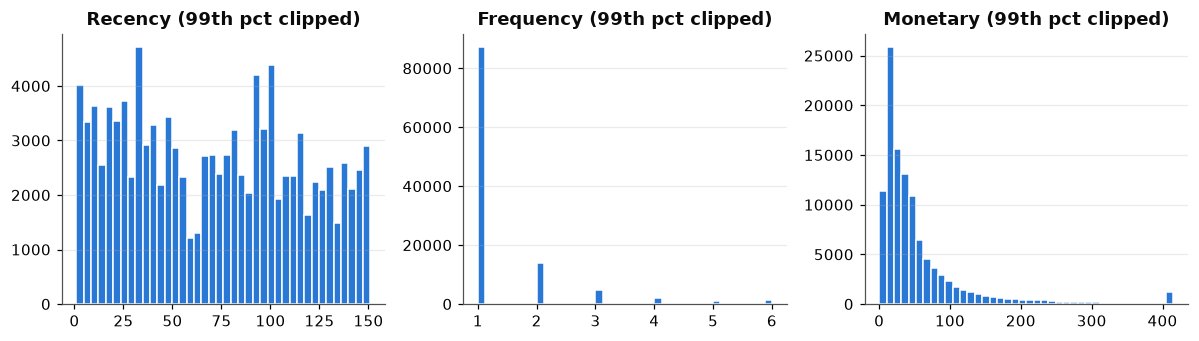

In [10]:
rfm_log = (rfm.withColumn("R_log", F.log1p("Recency"))
              .withColumn("F_log", F.log1p("Frequency"))
              .withColumn("M_log", F.log1p("Monetary")))

pdf = rfm.select("Recency", "Frequency", "Monetary").toPandas()   # one row per buyer: small enough to plot
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(pdf[col].clip(upper=pdf[col].quantile(0.99)), bins=40, color=PALETTE[0], edgecolor="white")
    ax.set_title(f"{col} (99th pct clipped)"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("outputs/rfm_distributions.png", dpi=150); plt.show()

## 5. Assemble and scale the features (MLlib)

In [11]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

assembler = VectorAssembler(inputCols=["R_log", "F_log", "M_log"], outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)

assembled = assembler.transform(rfm_log)
data = scaler.fit(assembled).transform(assembled).cache()
data.select("user_id", "Recency", "Frequency", "Monetary", "features").show(5, truncate=False)

+---------+-------+---------+--------+-----------------------------------------------------------+
|user_id  |Recency|Frequency|Monetary|features                                                   |
+---------+-------+---------+--------+-----------------------------------------------------------+
|558456872|142    |1        |89.51   |[1.0621101275167153,-0.4455242557265405,0.9936750231578027]|
|399967334|89     |1        |98.72   |[0.5703659833400643,-0.4455242557265405,1.0957041777422425]|
|556598973|149    |2        |107.93  |[1.1128639174495751,0.9580053925267075,1.1887137251879512] |
|514455276|22     |8        |325.07  |[-0.8785400249954561,4.76088482221542,2.343085336183629]   |
|465694378|16     |4        |242.9   |[-1.1995629746723317,2.7262436298148507,2.0373810884641643]|
+---------+-------+---------+--------+-----------------------------------------------------------+
only showing top 5 rows



## 6. Choose k: elbow method + Silhouette score

For each k from 2 to 8 we train K-Means and record:
* **WSSSE** (within-cluster sum of squared errors, `model.summary.trainingCost`): look for the "elbow"
* **Silhouette score** (`ClusteringEvaluator`, closer to 1 is better)

In [12]:
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction",
                                metricName="silhouette", distanceMeasure="squaredEuclidean")
scores = []
for k in range(2, 9):
    t0 = time.time()
    model = KMeans(k=k, seed=42, featuresCol="features", maxIter=50).fit(data)
    sil = evaluator.evaluate(model.transform(data))
    scores.append({"k": k, "wssse": model.summary.trainingCost, "silhouette": sil})
    print(f"k={k}:  WSSSE={model.summary.trainingCost:10.1f}   silhouette={sil:.4f}   ({time.time()-t0:.1f}s)")
scores = pd.DataFrame(scores)
RESULTS["k_scores"] = scores.round(4).to_dict(orient="records")

k=2:  WSSSE=  209251.1   silhouette=0.6620   (3.8s)


k=3:  WSSSE=  153483.2   silhouette=0.5479   (4.5s)


k=4:  WSSSE=  117250.2   silhouette=0.4895   (7.9s)


k=5:  WSSSE=  104815.7   silhouette=0.4515   (8.0s)


k=6:  WSSSE=   84312.7   silhouette=0.5036   (11.7s)


k=7:  WSSSE=   76665.5   silhouette=0.4715   (13.4s)


k=8:  WSSSE=   71364.5   silhouette=0.5073   (13.0s)


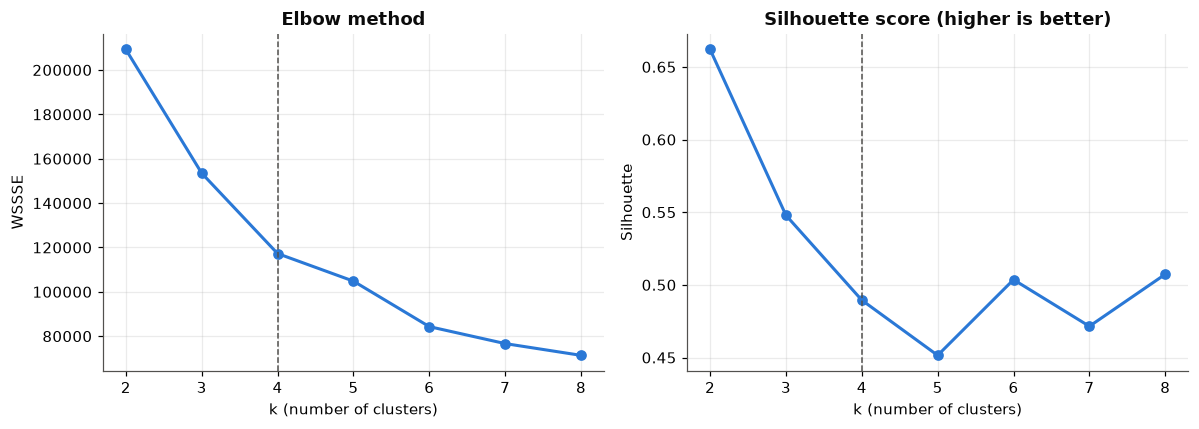

In [13]:
K_FINAL = 4   # chosen k (justified below)

# Two separate panels (two different scales -> never one dual-axis chart)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(scores.k, scores.wssse, color=PALETTE[0], lw=2, marker="o", ms=6)
a1.set(title="Elbow method", xlabel="k (number of clusters)", ylabel="WSSSE")
a2.plot(scores.k, scores.silhouette, color=PALETTE[0], lw=2, marker="o", ms=6)
a2.set(title="Silhouette score (higher is better)", xlabel="k (number of clusters)", ylabel="Silhouette")
for a in (a1, a2):
    a.axvline(K_FINAL, color="#52514e", ls="--", lw=1)
plt.tight_layout(); plt.savefig("outputs/k_selection.png", dpi=150); plt.show()

**Choosing k.** The Silhouette score is highest at k = 2 (≈0.66), but two segments ("buyers" vs "non-buyers") are too coarse for marketing. The WSSSE curve drops steeply up to **k = 4** (−56k from k=2→3, −36k from k=3→4) and then flattens (only −12k from k=4→5): that bend is the **elbow**. At k = 4 the Silhouette is still ≈0.49 (reasonable structure), and the four clusters map to four distinct, actionable RFM personas, so we use **k = 4**.

## 7. Train the final model and profile the clusters

In [14]:
final_model = KMeans(k=K_FINAL, seed=42, featuresCol="features", maxIter=50).fit(data)
segmented = final_model.transform(data).withColumnRenamed("prediction", "Cluster").cache()
final_sil = evaluator.setPredictionCol("Cluster").evaluate(segmented)
RESULTS.update(k_final=K_FINAL, final_silhouette=round(final_sil, 4))
print(f"Final model: k={K_FINAL}, silhouette={final_sil:.4f}")

profile = (segmented.groupBy("Cluster")
           .agg(F.count("*").alias("Customers"),
                F.round(F.avg("Recency"), 1).alias("AvgRecency"),
                F.round(F.avg("Frequency"), 2).alias("AvgFrequency"),
                F.round(F.avg("Monetary"), 1).alias("AvgMonetary"),
                F.round(F.sum("Monetary"), 0).alias("TotalRevenue"))
           .orderBy("Cluster"))
profile.show()

Final model: k=4, silhouette=0.4895


+-------+---------+----------+------------+-----------+------------+
|Cluster|Customers|AvgRecency|AvgFrequency|AvgMonetary|TotalRevenue|
+-------+---------+----------+------------+-----------+------------+
|      0|    39845|      87.6|        1.22|       69.3|   2760310.0|
|      1|    10835|      35.0|         4.0|      203.3|   2202442.0|
|      2|    41123|      89.4|        1.02|       15.9|    653526.0|
|      3|    18715|      14.5|        1.16|       39.1|    731990.0|
+-------+---------+----------+------------+-----------+------------+



### Naming the clusters

Clusters are named with a simple, explainable rule on the cluster averages:
1. highest average **Frequency** → **Champions** (repeat buyers who spend the most)
2. of the rest, lowest average **Recency** → **New / Promising** (just bought for the first time)
3. of the last two (both inactive for ~3 months), the higher average **Monetary** → **At-Risk** (spent well but haven't come back), the other → **Lost** (one small order, long ago)

In [15]:
prof = profile.toPandas()
names, rest = {}, prof.copy()
c = rest.loc[rest.AvgFrequency.idxmax()]; names[c.Cluster] = "Champions";       rest = rest.drop(c.name)
c = rest.loc[rest.AvgRecency.idxmin()];   names[c.Cluster] = "New / Promising"; rest = rest.drop(c.name)
c = rest.loc[rest.AvgMonetary.idxmax()];  names[c.Cluster] = "At-Risk";         rest = rest.drop(c.name)
names[rest.iloc[0].Cluster] = "Lost"
SEG_ORDER = ["Champions", "New / Promising", "At-Risk", "Lost"]
prof["Segment"] = prof.Cluster.map(names)
prof["CustomerShare%"] = (100 * prof.Customers / prof.Customers.sum()).round(1)
prof["RevenueShare%"] = (100 * prof.TotalRevenue / prof.TotalRevenue.sum()).round(1)
prof = prof.set_index("Segment").loc[SEG_ORDER].reset_index()
SEG_COLOR = dict(zip(SEG_ORDER, PALETTE))
RESULTS["segments"] = prof.to_dict(orient="records")
prof

,Segment,Cluster,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalRevenue,CustomerShare%,RevenueShare%
0,Champions,1,10835,35.0,4.00,203.3,2202442.0,9.8,34.7
1,New / Promising,3,18715,14.5,1.16,39.1,731990.0,16.9,11.5
2,At-Risk,0,39845,87.6,1.22,69.3,2760310.0,36.1,43.5
3,Lost,2,41123,89.4,1.02,15.9,653526.0,37.2,10.3


In [16]:
# Attach the segment name to every buyer (Spark join with a small broadcast lookup table)
name_df = spark.createDataFrame([(int(c), n) for c, n in names.items()], ["Cluster", "Segment"])
customers = segmented.join(F.broadcast(name_df), "Cluster").select(
    "user_id", "Recency", "Frequency", "Monetary", "Cluster", "Segment")
customers.groupBy("Segment").count().show()

seg_pd = customers.toPandas()   # one row per buyer, used for plots and the CSV export
seg_pd.sort_values("user_id").to_csv("outputs/customer_segments.csv", index=False)
print(f"Saved outputs/customer_segments.csv ({len(seg_pd):,} buyers)")

+---------------+-----+
|        Segment|count|
+---------------+-----+
|      Champions|10835|
|        At-Risk|39845|
|           Lost|41123|
|New / Promising|18715|
+---------------+-----+



Saved outputs/customer_segments.csv (110,518 buyers)


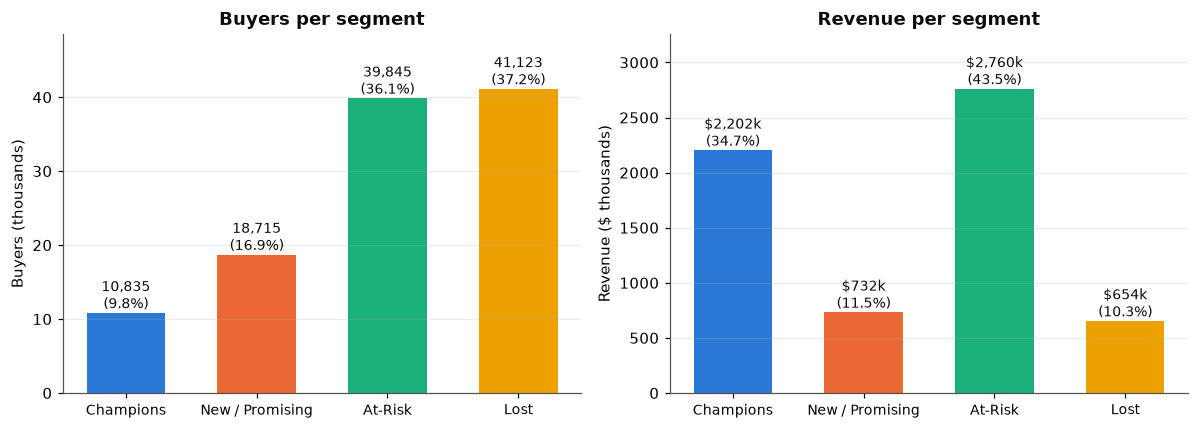

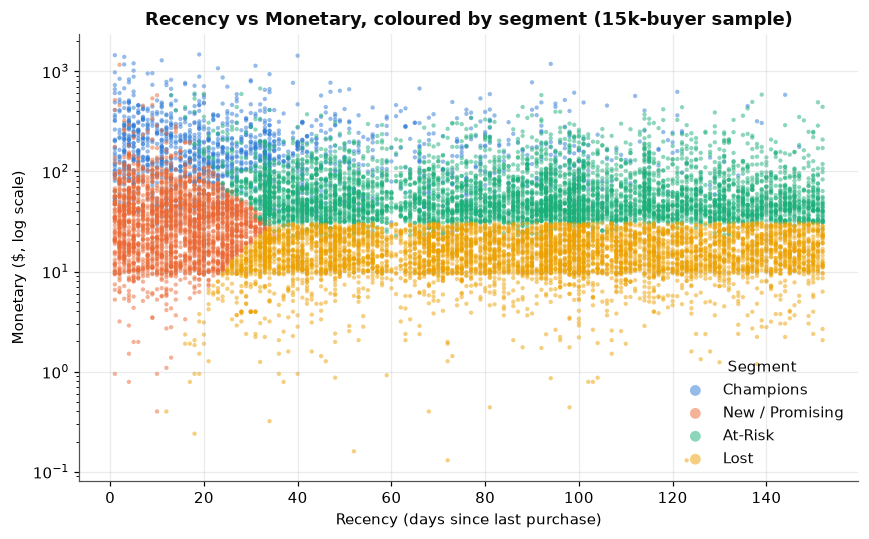

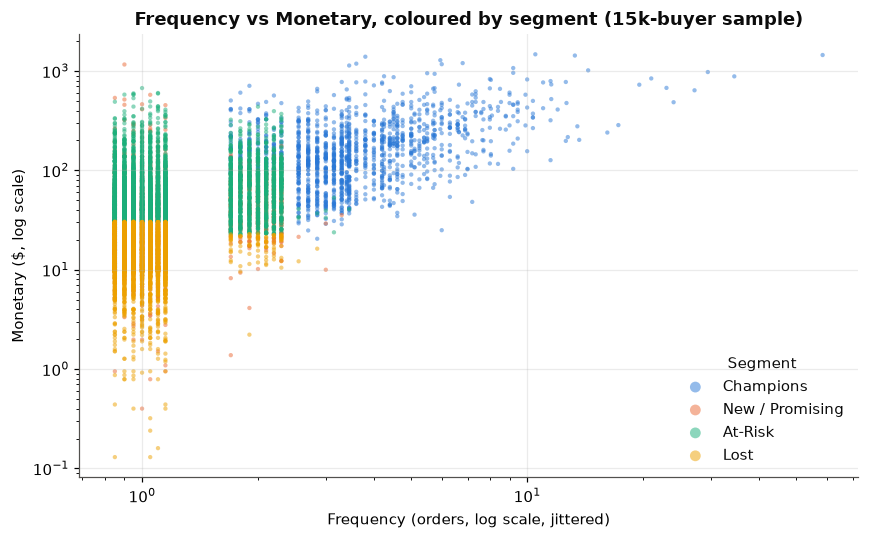

In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
cols = [SEG_COLOR[s] for s in prof.Segment]
a1.bar(prof.Segment, prof.Customers / 1e3, color=cols, width=0.6)
a1.set(title="Buyers per segment", ylabel="Buyers (thousands)")
for i, (c, p) in enumerate(zip(prof.Customers, prof["CustomerShare%"])):
    a1.text(i, c / 1e3, f"{c:,}\n({p}%)", ha="center", va="bottom", fontsize=9)
a2.bar(prof.Segment, prof.TotalRevenue / 1e3, color=cols, width=0.6)
a2.set(title="Revenue per segment", ylabel="Revenue ($ thousands)")
for i, (r, p) in enumerate(zip(prof.TotalRevenue / 1e3, prof["RevenueShare%"])):
    a2.text(i, r, f"${r:,.0f}k\n({p}%)", ha="center", va="bottom", fontsize=9)
for a in (a1, a2):
    a.grid(axis="x", visible=False); a.margins(y=0.18); a.tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.savefig("outputs/segment_sizes.png", dpi=150); plt.show()

plot_df = seg_pd.sample(n=min(len(seg_pd), 15000), random_state=42)   # sample so the scatter stays readable
for xcol, xlog, fname in [("Recency", False, "segments_scatter.png"), ("Frequency", True, "segments_scatter_fm.png")]:
    fig, ax = plt.subplots(figsize=(8, 5))
    for s in SEG_ORDER:
        d = plot_df[plot_df.Segment == s]
        jitter = d[xcol] * (1 + 0.15 * (pd.Series(range(len(d)), index=d.index) % 7 - 3) / 3) if xlog else d[xcol]
        ax.scatter(jitter, d.Monetary, s=8, alpha=0.5, color=SEG_COLOR[s], label=s, edgecolors="none")
    ax.set_yscale("log")
    if xlog: ax.set_xscale("log")
    xl = "Recency (days since last purchase)" if xcol == "Recency" else "Frequency (orders, log scale, jittered)"
    ax.set(title=f"{xcol} vs Monetary, coloured by segment (15k-buyer sample)", xlabel=xl, ylabel="Monetary ($, log scale)")
    ax.legend(title="Segment", markerscale=2.5, frameon=False)
    plt.tight_layout(); plt.savefig(f"outputs/{fname}", dpi=150); plt.show()

## 8. Business actions per segment

| Segment | Profile | Suggested action |
|---|---|---|
| **Champions** | Repeat buyers (≈4 orders), highest spend, bought within ~1 month | VIP/loyalty tier, early access to new products, referral rewards |
| **New / Promising** | First purchase in the last ~2 weeks, small basket | Welcome series and a second-purchase coupon to build the habit |
| **At-Risk** | One or two good-sized orders, but no purchase for ~3 months | Personalised win-back emails with products from their favourite brands |
| **Lost** | One small order ~3 months ago | Low-cost reactivation (newsletter only); don't spend paid-ads budget here |

**Limitations:** 5-month snapshot of one shop; k chosen partly by judgement; RFM ignores browsing behaviour, product mix and returns; run on a single-node Spark (Colab), not a real cluster.
**Future scope:** Spark Structured Streaming to update segments as events arrive; add behavioural features (views, cart abandonment, brand affinity); compare with Bisecting K-Means / Gaussian Mixture in MLlib; run on a multi-node cluster (Databricks / EMR).

In [18]:
with open("outputs/results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)
print(json.dumps({k: v for k, v in RESULTS.items() if k not in ("k_scores", "segments")}, indent=2, default=str))
print("\nFiles in outputs/:", sorted(os.listdir("outputs")))

{
  "data_size_gb": 2.27,
  "n_files": 5,
  "raw_rows": 20692840,
  "raw_partitions": 25,
  "scan_seconds": 6.3,
  "clean_rows": 19493208,
  "removed_rows": 1199632,
  "removed_pct": 5.8,
  "clean_seconds": 33.3,
  "users": 1637770,
  "sessions": 4520284,
  "products": 53903,
  "brands": 273,
  "first_date": "2019-10-01",
  "last_date": "2020-02-29",
  "event_counts": {
    "view": 9626268,
    "cart": 5612289,
    "remove_from_cart": 2968669,
    "purchase": 1285982
  },
  "user_counts": {
    "view": 1596359,
    "cart": 397390,
    "remove_from_cart": 183002,
    "purchase": 110518
  },
  "view_to_purchase_user_pct": 6.9,
  "revenue": 6348268.0,
  "purchase_events": 1285982,
  "peak_month": "2019-11",
  "reference_date": "2020-03-01",
  "customers": 110518,
  "k_final": 4,
  "final_silhouette": 0.4895
}

Files in outputs/: ['customer_segments.csv', 'eda_event_funnel.png', 'eda_monthly_revenue.png', 'eda_top_brands.png', 'k_selection.png', 'results.json', 'rfm_distributions.png', 'se

## 9. Live demo cells (run these in front of the audience)

These cells reuse the cached data from the run above, so each one finishes in a few seconds.
Run the whole notebook **before** the presentation, keep the Colab tab open, then run these live.

In [19]:
# LIVE 1: ad-hoc SparkSQL on the segmented buyers (a few seconds, the data is cached)
customers.createOrReplaceTempView("segments")
spark.sql("""
    SELECT Segment,
           COUNT(*)                   AS buyers,
           ROUND(AVG(Recency), 0)     AS avg_recency_days,
           ROUND(AVG(Frequency), 2)   AS avg_orders,
           ROUND(AVG(Monetary), 1)    AS avg_spend,
           ROUND(SUM(Monetary), 0)    AS revenue
    FROM segments
    GROUP BY Segment
    ORDER BY revenue DESC""").show()

+---------------+------+----------------+----------+---------+---------+
|        Segment|buyers|avg_recency_days|avg_orders|avg_spend|  revenue|
+---------------+------+----------------+----------+---------+---------+
|        At-Risk| 39845|            88.0|      1.22|     69.3|2760310.0|
|      Champions| 10835|            35.0|       4.0|    203.3|2202442.0|
|New / Promising| 18715|            14.0|      1.16|     39.1| 731990.0|
|           Lost| 41123|            89.0|      1.02|     15.9| 653526.0|
+---------------+------+----------------+----------+---------+---------+



In [20]:
# LIVE 2: look up one real buyer: their RFM values and segment
LOOKUP_USER = 420629649          # change to any user_id from the table above
customers.filter(F.col("user_id") == LOOKUP_USER).show()
spark.sql(f"""
    SELECT event_type, COUNT(*) AS events, ROUND(SUM(price), 2) AS value
    FROM events WHERE user_id = {LOOKUP_USER}
    GROUP BY event_type ORDER BY events DESC""").show()

+---------+-------+---------+--------+-------+---------+
|  user_id|Recency|Frequency|Monetary|Cluster|  Segment|
+---------+-------+---------+--------+-------+---------+
|420629649|      7|        9|   601.7|      1|Champions|
+---------+-------+---------+--------+-------+---------+



+----------------+------+-------+
|      event_type|events|  value|
+----------------+------+-------+
|            cart|   553|1988.43|
|            view|   422|4599.68|
|remove_from_cart|   417|1693.47|
|        purchase|   131|  601.7|
+----------------+------+-------+



In [21]:
# LIVE 3: put a NEW customer through the same pipeline (log1p -> assembler -> scaler -> K-Means)
scaler_model = scaler.fit(assembled)   # same mean/std as above (deterministic)

def predict_segment(recency_days, orders, spend):
    new = spark.createDataFrame([(int(recency_days), int(orders), float(spend))],
                                ["Recency", "Frequency", "Monetary"])
    new = (new.withColumn("R_log", F.log1p("Recency"))
              .withColumn("F_log", F.log1p("Frequency"))
              .withColumn("M_log", F.log1p("Monetary")))
    cluster = final_model.transform(scaler_model.transform(assembler.transform(new))).first().prediction
    return names[cluster]

for r, f, m in [(5, 6, 400), (7, 1, 25), (90, 2, 150), (100, 1, 10)]:
    print(f"Recency={r:>3} days  Orders={f}  Spend=${m:>4}  ->  {predict_segment(r, f, m)}")

Recency=  5 days  Orders=6  Spend=$ 400  ->  Champions


Recency=  7 days  Orders=1  Spend=$  25  ->  New / Promising


Recency= 90 days  Orders=2  Spend=$ 150  ->  At-Risk


Recency=100 days  Orders=1  Spend=$  10  ->  Lost


In [22]:
# Stop Spark only after the demo is over (running this ends the session's Spark context)
# spark.stop()